In [118]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report
import time

# Build different Normalities

In [119]:
def load_timeseries_from_folders(normality, folder_list):
    all_dfs = []
    folders_to_read = folder_list[:normality]

    for folder in folders_to_read:
        folder_path = os.path.join("..", "TSB-UAD-Public", folder)

        files = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]
        
        if not files:
            print(f"Folder {folder} is empty or contains no files.")
            continue

        filename = files[0]
        file_path = os.path.join(folder_path, filename)

        try:
            df = pd.read_csv(file_path, header=None).dropna()
            df.columns = ['measurement', 'anomaly']
            print(f"Read file {filename} from folder {folder} ({df.shape[0]} rows).")
            all_dfs.append(df)
        except Exception as e:
            print(f"Error reading file {file_path}: {e}")

    if all_dfs:
        full_df = pd.concat(all_dfs, ignore_index=True)
        print("\nData merge completed. Combine df has",full_df.shape[0]," number of rows")
        return full_df
    else:
        print("No valid data found.")
        return pd.DataFrame()

folders = ["YAHOO", "SensorScope", "GHL", "Genesis"]
normality = 3

result = load_timeseries_from_folders(normality, folders)
result


Read file YahooA3Benchmark-TS100_data.out from folder YAHOO (1680 rows).
Read file stb-10.test.out from folder SensorScope (29518 rows).
Read file 01_Lev_fault_Temp_corr_seed_11_vars_23.test.csv@10.out from folder GHL (200001 rows).

Data merge completed. Combine df has 231199  number of rows


,measurement,anomaly
0,6.470061,0
1,80.972293,0
2,159.014680,0
3,214.721803,0
4,201.695834,0
...,...,...
231194,0.000000,0
231195,0.000000,0
231196,0.000000,0
231197,0.000000,0


# Isolation forest Offline

In [120]:
X = result[['measurement']]

model = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)

start_time = time.time()
model.fit(X)

preds = model.predict(X)

result['prediction'] = (preds == -1).astype(int)

end_time = time.time()
elapsed_time = end_time - start_time


print(classification_report(result['anomaly'], result['prediction']))
print(f"runtime: {elapsed_time / 60:.4f} minutes")



              precision    recall  f1-score   support

           0       0.98      0.96      0.97    224486
           1       0.21      0.35      0.26      6713

    accuracy                           0.94    231199
   macro avg       0.59      0.66      0.61    231199
weighted avg       0.96      0.94      0.95    231199

runtime: 0.2944 minutes


In [121]:
from sklearn.metrics import classification_report, f1_score,roc_auc_score, precision_score, recall_score

precision = precision_score(result['anomaly'], result['prediction'])
recall = recall_score(result['anomaly'], result['prediction'])
f1 = f1_score(result['anomaly'], result['prediction'])
roc_auc = roc_auc_score(result['anomaly'], result['prediction'])

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Precision: 0.2056
Recall:    0.3538
F1 Score:  0.2601
ROC-AUC:   0.6565


# Isolation forest Streaming

In [122]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report

batch_size = 5000
contamination = 0.09

X = result[['measurement']].copy()
y_true = result['anomaly'].values
n_samples = len(X)

all_preds = np.zeros(n_samples, dtype=int)

start_time = time.time()
for batch_idx, start in enumerate(range(0, n_samples, batch_size)):
    end = min(start + batch_size, n_samples)
    X_batch = X.iloc[start:end]

    print(f"Batch {batch_idx+1}: samples {start} to {end-1}...")

    model = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
    model.fit(X_batch)

    preds = model.predict(X_batch)
    preds = (preds == -1).astype(int)  # 1 = anomaly, 0 = normal

    all_preds[start:end] = preds

print("\nAll batches processed.\n")
end_time = time.time()
elapsed_time = end_time - start_time


result['prediction'] = all_preds

print("Final Evaluation (Overall):")
print(classification_report(y_true, result['prediction']))
print(f"runtime: {elapsed_time / 60:.4f} minutes")

Batch 1: samples 0 to 4999...
Batch 2: samples 5000 to 9999...
Batch 3: samples 10000 to 14999...
Batch 4: samples 15000 to 19999...
Batch 5: samples 20000 to 24999...
Batch 6: samples 25000 to 29999...
Batch 7: samples 30000 to 34999...
Batch 8: samples 35000 to 39999...
Batch 9: samples 40000 to 44999...
Batch 10: samples 45000 to 49999...
Batch 11: samples 50000 to 54999...
Batch 12: samples 55000 to 59999...
Batch 13: samples 60000 to 64999...
Batch 14: samples 65000 to 69999...
Batch 15: samples 70000 to 74999...
Batch 16: samples 75000 to 79999...
Batch 17: samples 80000 to 84999...
Batch 18: samples 85000 to 89999...
Batch 19: samples 90000 to 94999...
Batch 20: samples 95000 to 99999...
Batch 21: samples 100000 to 104999...
Batch 22: samples 105000 to 109999...
Batch 23: samples 110000 to 114999...
Batch 24: samples 115000 to 119999...
Batch 25: samples 120000 to 124999...
Batch 26: samples 125000 to 129999...
Batch 27: samples 130000 to 134999...
Batch 28: samples 135000 to 13

In [123]:
precision = precision_score(result['anomaly'], result['prediction'])
recall = recall_score(result['anomaly'], result['prediction'])
f1 = f1_score(result['anomaly'], result['prediction'])
roc_auc = roc_auc_score(result['anomaly'], result['prediction'])

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Precision: 0.2184
Recall:    0.1025
F1 Score:  0.1395
ROC-AUC:   0.5458


# HISTORY 

Batch 1: samples 0 to 4999...
Batch 2: samples 5000 to 9999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 3: samples 10000 to 14999...
   Precision: 0.186, Recall: 0.083, F1: 0.114
Batch 4: samples 15000 to 19999...
   Precision: 0.152, Recall: 0.073, F1: 0.098
Batch 5: samples 20000 to 24999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 6: samples 25000 to 29999...
   Precision: 0.384, Recall: 0.590, F1: 0.465
Batch 7: samples 30000 to 34999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 8: samples 35000 to 39999...
Batch 9: samples 40000 to 44999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 10: samples 45000 to 49999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 11: samples 50000 to 54999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 12: samples 55000 to 59999...
Batch 13: samples 60000 to 64999...
   Precision: 0.000, Recall: 0.000, F1: 0.000
Batch 14: samples 65000 to 69999...
Batch 15: samples 70000 to 74999...
   Precision: 0.

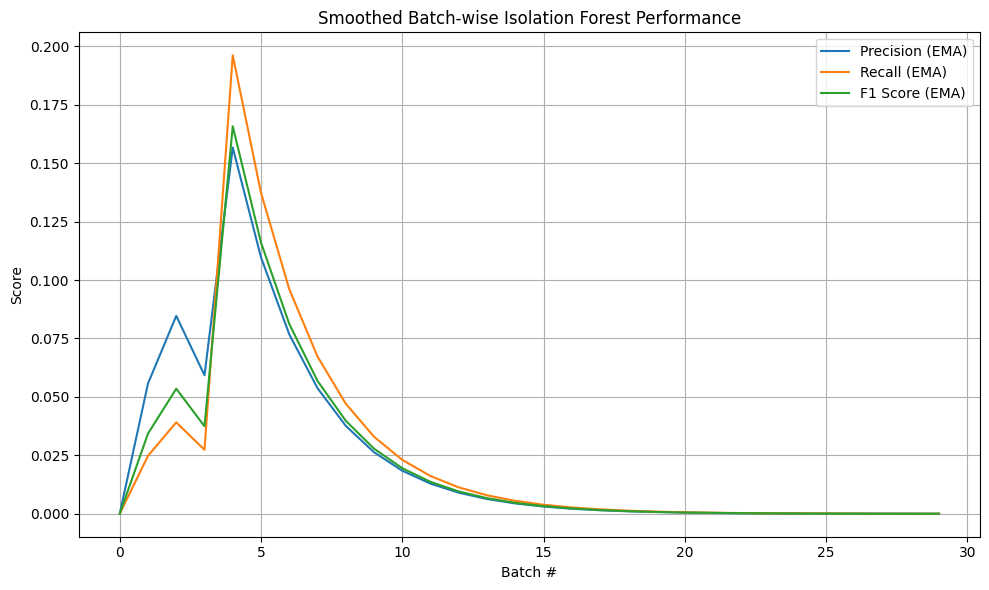

In [124]:
import numpy as np
import pandas as pd
import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt

batch_size = 5000
max_history = 20000
initial_contamination = 0.09

X = result[['measurement']].copy()
y_true = result['anomaly'].values
n_samples = len(X)

all_preds = np.zeros(n_samples, dtype=int)
history = pd.DataFrame()
history_labels = []

precisions, recalls, f1s = [], [], []

start_time = time.time()

for batch_idx, start in enumerate(range(0, n_samples, batch_size)):
    end = min(start + batch_size, n_samples)
    X_batch_raw = X.iloc[start:end]
    y_batch_raw = y_true[start:end]

    print(f"Batch {batch_idx+1}: samples {start} to {end-1}...")

    combined = pd.concat([history[['measurement']] if not history.empty else pd.DataFrame(), X_batch_raw])
    combined = combined.copy()

    combined['rolling_mean_10'] = combined['measurement'].rolling(window=10).mean()
    combined['rolling_std_10'] = combined['measurement'].rolling(window=10).std()
    combined['zscore_10'] = (combined['measurement'] - combined['rolling_mean_10']) / combined['rolling_std_10']
    combined['lag_1'] = combined['measurement'].shift(1)
    combined['lag_diff'] = combined['measurement'] - combined['lag_1']
    combined['rolling_min_10'] = combined['measurement'].rolling(window=10).min()
    combined['rolling_max_10'] = combined['measurement'].rolling(window=10).max()
    combined['rolling_median_10'] = combined['measurement'].rolling(window=10).median()

    combined = combined.dropna().reset_index(drop=False) 

    if combined.empty:
        all_preds[start:end] = 0
        continue

    if not history.empty:
        history_len = min(len(history), len(combined))
        history = combined.iloc[:history_len].reset_index(drop=True)
        X_batch = combined.iloc[history_len:].reset_index(drop=True)

        if X_batch.empty:
            all_preds[start:end] = 0
            continue

        X_batch_orig_indices = X_batch['index'].values.astype(int)
        y_batch = y_true[X_batch_orig_indices]
        history_labels = (history_labels + list(y_batch))[-max_history:]

    else:
        history = combined.reset_index(drop=True)
        history_labels = list(y_batch_raw)
        all_preds[start:end] = 0
        continue

    labeled_anomaly_ratio = np.mean(history_labels) if history_labels else initial_contamination
    contamination = max(0.01, min(0.2, labeled_anomaly_ratio * 2))


    model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        max_samples='auto',
        random_state=42,
        bootstrap=False
    )
    feature_cols = ['measurement', 'rolling_mean_10', 'rolling_std_10', 'zscore_10',
                    'lag_1', 'lag_diff', 'rolling_min_10', 'rolling_max_10', 'rolling_median_10']
    model.fit(history[feature_cols])


    preds = (model.predict(X_batch[feature_cols]) == -1).astype(int)
    all_preds[X_batch_orig_indices] = preds


    precision = precision_score(y_batch, preds, zero_division=0)
    recall = recall_score(y_batch, preds, zero_division=0)
    f1 = f1_score(y_batch, preds, zero_division=0)

    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)

    print(f"   Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

    history = pd.concat([history, X_batch]).tail(max_history).reset_index(drop=True)
    history_labels = (history_labels + list(y_batch))[-max_history:]

end_time = time.time()
elapsed_time = end_time - start_time
print("\nAll batches processed.\n")

result['prediction'] = all_preds

print("Final Evaluation (Overall):")
print(classification_report(y_true, result['prediction']))
print(f"Total runtime: {elapsed_time / 60:.2f} minutes")

def ema(series, alpha=0.3):
    result = []
    prev = series[0]
    for val in series:
        prev = alpha * val + (1 - alpha) * prev
        result.append(prev)
    return result

plt.figure(figsize=(10, 6))
plt.plot(ema(precisions), label='Precision (EMA)')
plt.plot(ema(recalls), label='Recall (EMA)')
plt.plot(ema(f1s), label='F1 Score (EMA)')
plt.xlabel('Batch #')
plt.ylabel('Score')
plt.title('Smoothed Batch-wise Isolation Forest Performance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [125]:
precision = precision_score(result['anomaly'], result['prediction'])
recall = recall_score(result['anomaly'], result['prediction'])
f1 = f1_score(result['anomaly'], result['prediction'])
roc_auc = roc_auc_score(result['anomaly'], result['prediction'])

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Precision: 0.3002
Recall:    0.2226
F1 Score:  0.2556
ROC-AUC:   0.6035
